<a href="https://colab.research.google.com/github/mubashirbappi5/ml-archive/blob/main/Ml_P2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [115]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import  warnings
warnings.filterwarnings('ignore')


In [116]:
df = pd.read_csv('heart.csv')
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


**EDA / Data clean**

In [117]:
df.columns

Index(['Age', 'Sex', 'ChestPainType', 'RestingBP', 'Cholesterol', 'FastingBS',
       'RestingECG', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ST_Slope',
       'HeartDisease'],
      dtype='object')

In [118]:
df.shape

(918, 12)

In [119]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    object 
 2   ChestPainType   918 non-null    object 
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    object 
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    object 
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    object 
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 86.2+ KB


In [120]:
df.isnull().sum()

,0
Age,0
Sex,0
ChestPainType,0
RestingBP,0
Cholesterol,0
FastingBS,0
RestingECG,0
MaxHR,0
ExerciseAngina,0
Oldpeak,0


In [121]:
df.describe()

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
count,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000
mean,53.510893,132.396514,198.799564,0.233115,136.809368,0.887364,0.553377
std,9.432617,18.514154,109.384145,0.423046,25.460334,1.066570,0.497414
min,28.000000,0.000000,0.000000,0.000000,60.000000,-2.600000,0.000000
25%,47.000000,120.000000,173.250000,0.000000,120.000000,0.000000,0.000000
50%,54.000000,130.000000,223.000000,0.000000,138.000000,0.600000,1.000000
75%,60.000000,140.000000,267.000000,0.000000,156.000000,1.500000,1.000000
max,77.000000,200.000000,603.000000,1.000000,202.000000,6.200000,1.000000


In [122]:
df.duplicated().sum()

np.int64(0)

<Axes: xlabel='HeartDisease'>

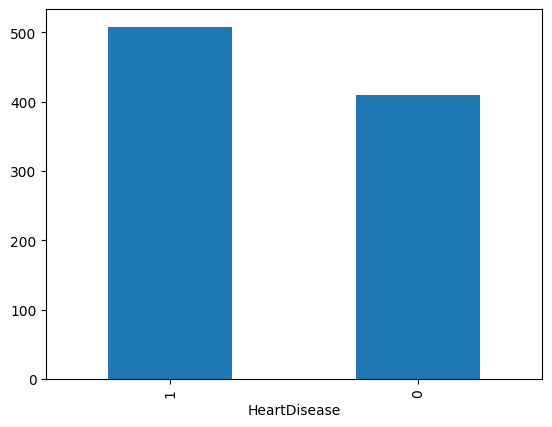

In [123]:
df['HeartDisease'].value_counts().plot(kind='bar')

In [124]:
def plotting(var,num):
  plt.subplot(2,2,num)
  sns.histplot(df[var],kde=True)




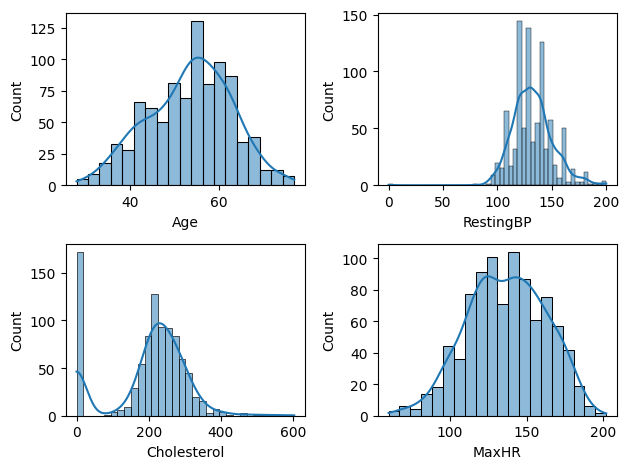

In [125]:
plotting('Age',1)
plotting('RestingBP',2)
plotting('Cholesterol',3)
plotting('MaxHR',4)
plt.tight_layout()

In [126]:
ch_mean =df.loc[df['Cholesterol']!=0,'Cholesterol'].mean()
ch_mean


np.float64(244.6353887399464)

In [127]:
df['Cholesterol']=df['Cholesterol'].replace(0,ch_mean)
df['Cholesterol']=df['Cholesterol'].round(2)
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289.0,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180.0,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283.0,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214.0,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195.0,0,Normal,122,N,0.0,Up,0


In [128]:
restingBp_mean =df.loc[df['RestingBP']!=0,'RestingBP'].mean()
df['RestingBP']=df['RestingBP'].replace(0,restingBp_mean)
df['RestingBP']=df['RestingBP'].round(2)
df['RestingBP']

,RestingBP
0,140.0
1,160.0
2,130.0
3,138.0
4,150.0
...,...
913,110.0
914,144.0
915,130.0
916,130.0


In [129]:
def plotting(var,num):
  plt.subplot(2,2,num)
  sns.histplot(df[var],kde=True)

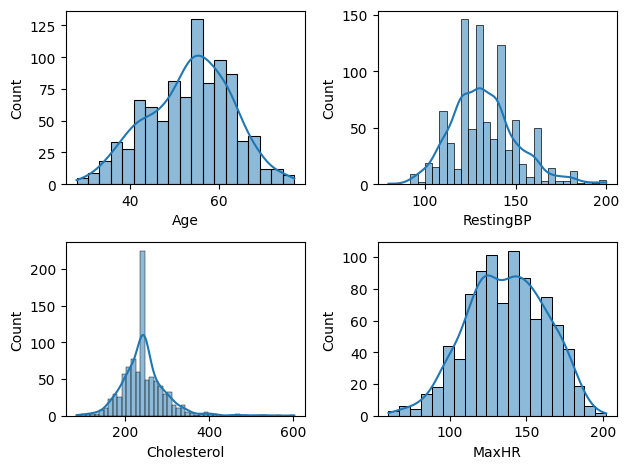

In [130]:
plotting('Age',1)
plotting('RestingBP',2)
plotting('Cholesterol',3)
plotting('MaxHR',4)
plt.tight_layout()

<Axes: xlabel='Sex', ylabel='count'>

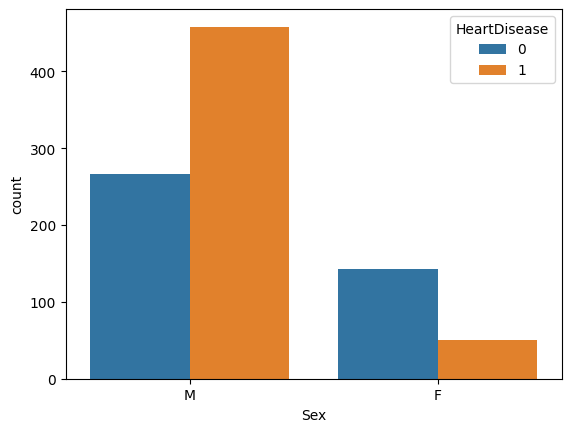

In [131]:
sns.countplot(x=df['Sex'],hue= df['HeartDisease'])

<Axes: xlabel='ChestPainType', ylabel='count'>

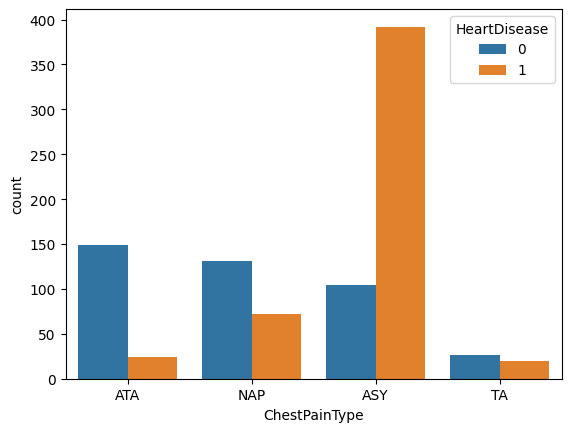

In [132]:
sns.countplot(x=df['ChestPainType'],hue=df['HeartDisease'])

<Axes: xlabel='FastingBS', ylabel='count'>

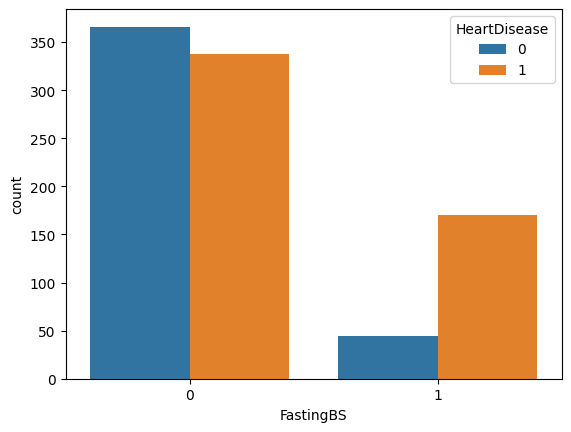

In [133]:
sns.countplot(x=df['FastingBS'],hue=df['HeartDisease'])

<Axes: xlabel='HeartDisease', ylabel='Cholesterol'>

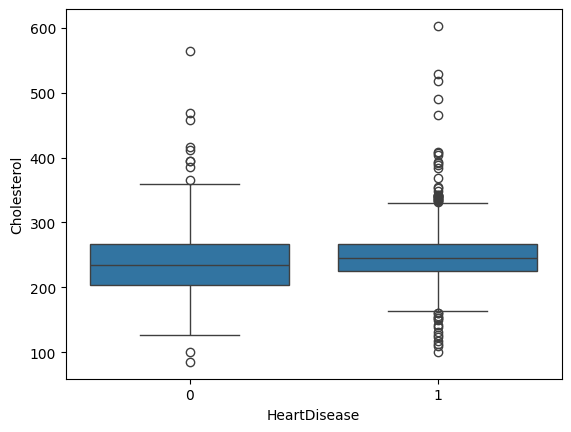

In [134]:
sns.boxplot(x='HeartDisease',y='Cholesterol',data=df)

<Axes: xlabel='HeartDisease', ylabel='Age'>

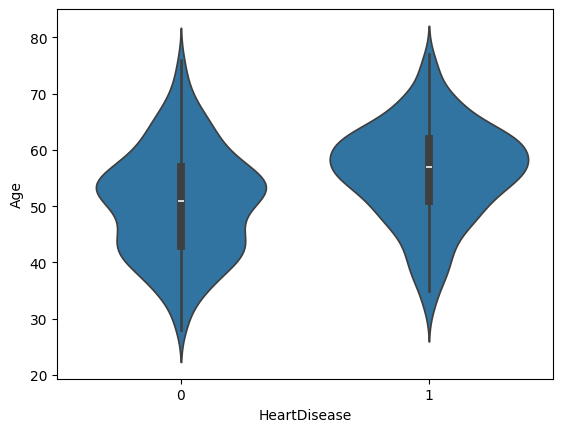

In [135]:
sns.violinplot(x='HeartDisease',y='Age',data=df)

<Axes: >

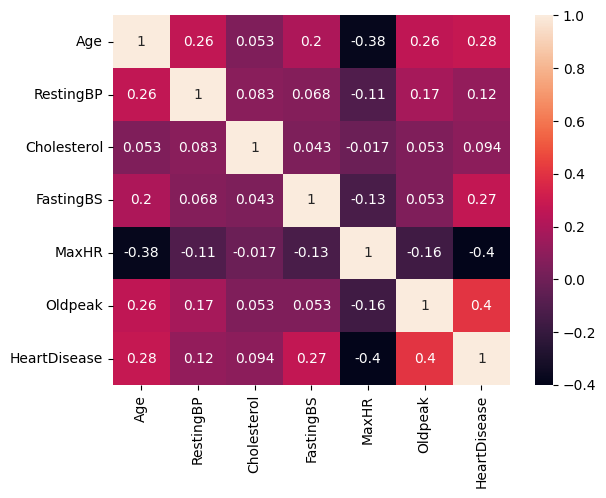

In [136]:
sns.heatmap(df.corr(numeric_only=True),annot=True)

Data pre **procesing**

In [137]:
df_encode = pd.get_dummies(df,drop_first=True)
df_encode = df_encode.astype(int)
df_encode.head()


,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease,Sex_M,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_Normal,RestingECG_ST,ExerciseAngina_Y,ST_Slope_Flat,ST_Slope_Up
0,40,140,289,0,172,0,0,1,1,0,0,1,0,0,0,1
1,49,160,180,0,156,1,1,0,0,1,0,1,0,0,1,0
2,37,130,283,0,98,0,0,1,1,0,0,0,1,0,0,1
3,48,138,214,0,108,1,1,0,0,0,0,1,0,1,1,0
4,54,150,195,0,122,0,0,1,0,1,0,1,0,0,0,1


In [138]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
numerical_cols = ['Age','RestingBP','Cholesterol','MaxHR','Oldpeak']
df_encode[numerical_cols] = scaler.fit_transform(df_encode[numerical_cols])
df_encode.head()


,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease,Sex_M,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_Normal,RestingECG_ST,ExerciseAngina_Y,ST_Slope_Flat,ST_Slope_Up
0,-1.433140,0.414885,0.834754,0,1.382928,-0.727592,0,1,1,0,0,1,0,0,0,1
1,-0.478484,1.527224,-1.210675,0,0.754157,0.282891,1,0,0,1,0,1,0,0,1,0
2,-1.751359,-0.141284,0.722161,0,-1.525138,-0.727592,0,1,1,0,0,0,1,0,0,1
3,-0.584556,0.303651,-0.572651,0,-1.132156,0.282891,1,0,0,0,0,1,0,1,1,0
4,0.051881,0.971054,-0.929194,0,-0.581981,-0.727592,0,1,0,1,0,1,0,0,0,1


In [139]:
df['AgeGroup'] = pd.cut(
    df['Age'],
    bins=[0, 30, 40, 50, 60, 100],
    labels=['Young', 'Adult', 'MiddleAge',
            'Senior', 'Old']
)

df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease,AgeGroup
0,40,M,ATA,140.0,289.0,0,Normal,172,N,0.0,Up,0,Adult
1,49,F,NAP,160.0,180.0,0,Normal,156,N,1.0,Flat,1,MiddleAge
2,37,M,ATA,130.0,283.0,0,ST,98,N,0.0,Up,0,Adult
3,48,F,ASY,138.0,214.0,0,Normal,108,Y,1.5,Flat,1,MiddleAge
4,54,M,NAP,150.0,195.0,0,Normal,122,N,0.0,Up,0,Senior


In [140]:
df['MaxHR_Ratio'] = df['MaxHR'] / (220 - df['Age'])
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease,AgeGroup,MaxHR_Ratio
0,40,M,ATA,140.0,289.0,0,Normal,172,N,0.0,Up,0,Adult,0.955556
1,49,F,NAP,160.0,180.0,0,Normal,156,N,1.0,Flat,1,MiddleAge,0.912281
2,37,M,ATA,130.0,283.0,0,ST,98,N,0.0,Up,0,Adult,0.535519
3,48,F,ASY,138.0,214.0,0,Normal,108,Y,1.5,Flat,1,MiddleAge,0.627907
4,54,M,NAP,150.0,195.0,0,Normal,122,N,0.0,Up,0,Senior,0.734940


In [141]:
df['Has_ST_Depression'] = (
    df['Oldpeak'] > 0
).astype(int)

df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease,AgeGroup,MaxHR_Ratio,Has_ST_Depression
0,40,M,ATA,140.0,289.0,0,Normal,172,N,0.0,Up,0,Adult,0.955556,0
1,49,F,NAP,160.0,180.0,0,Normal,156,N,1.0,Flat,1,MiddleAge,0.912281,1
2,37,M,ATA,130.0,283.0,0,ST,98,N,0.0,Up,0,Adult,0.535519,0
3,48,F,ASY,138.0,214.0,0,Normal,108,Y,1.5,Flat,1,MiddleAge,0.627907,1
4,54,M,NAP,150.0,195.0,0,Normal,122,N,0.0,Up,0,Senior,0.734940,0


In [142]:
df['Oldpeak_Angina'] = (
    df['Oldpeak'] *
    (df['ExerciseAngina'] == 'Y').astype(int)
)

In [143]:
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease,AgeGroup,MaxHR_Ratio,Has_ST_Depression,Oldpeak_Angina
0,40,M,ATA,140.0,289.0,0,Normal,172,N,0.0,Up,0,Adult,0.955556,0,0.0
1,49,F,NAP,160.0,180.0,0,Normal,156,N,1.0,Flat,1,MiddleAge,0.912281,1,0.0
2,37,M,ATA,130.0,283.0,0,ST,98,N,0.0,Up,0,Adult,0.535519,0,0.0
3,48,F,ASY,138.0,214.0,0,Normal,108,Y,1.5,Flat,1,MiddleAge,0.627907,1,1.5
4,54,M,NAP,150.0,195.0,0,Normal,122,N,0.0,Up,0,Senior,0.734940,0,0.0


In [144]:
df_encode = pd.get_dummies(
    df,
    drop_first=True,
    dtype=int
)

df_encode.head()

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease,MaxHR_Ratio,Has_ST_Depression,Oldpeak_Angina,...,ChestPainType_TA,RestingECG_Normal,RestingECG_ST,ExerciseAngina_Y,ST_Slope_Flat,ST_Slope_Up,AgeGroup_Adult,AgeGroup_MiddleAge,AgeGroup_Senior,AgeGroup_Old
0,40,140.0,289.0,0,172,0.0,0,0.955556,0,0.0,...,0,1,0,0,0,1,1,0,0,0
1,49,160.0,180.0,0,156,1.0,1,0.912281,1,0.0,...,0,1,0,0,1,0,0,1,0,0
2,37,130.0,283.0,0,98,0.0,0,0.535519,0,0.0,...,0,0,1,0,0,1,1,0,0,0
3,48,138.0,214.0,0,108,1.5,1,0.627907,1,1.5,...,0,1,0,1,1,0,0,1,0,0
4,54,150.0,195.0,0,122,0.0,0,0.734940,0,0.0,...,0,1,0,0,0,1,0,0,1,0


In [145]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

numerical_cols = [
    'Age', 'RestingBP', 'Cholesterol',
    'MaxHR', 'Oldpeak'
]

df_encode[numerical_cols] = scaler.fit_transform(
    df_encode[numerical_cols]
)

In [146]:
df_encode.head()

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease,MaxHR_Ratio,Has_ST_Depression,Oldpeak_Angina,...,ChestPainType_TA,RestingECG_Normal,RestingECG_ST,ExerciseAngina_Y,ST_Slope_Flat,ST_Slope_Up,AgeGroup_Adult,AgeGroup_MiddleAge,AgeGroup_Senior,AgeGroup_Old
0,-1.433140,0.414853,0.832513,0,1.382928,-0.832432,0,0.955556,0,0.0,...,0,1,0,0,0,1,1,0,0,0
1,-0.478484,1.527192,-1.212938,0,0.754157,0.105664,1,0.912281,1,0.0,...,0,1,0,0,1,0,0,1,0,0
2,-1.751359,-0.141317,0.719919,0,-1.525138,-0.832432,0,0.535519,0,0.0,...,0,0,1,0,0,1,1,0,0,0
3,-0.584556,0.303619,-0.574908,0,-1.132156,0.574711,1,0.627907,1,1.5,...,0,1,0,1,1,0,0,1,0,0
4,0.051881,0.971022,-0.931454,0,-0.581981,-0.832432,0,0.734940,0,0.0,...,0,1,0,0,0,1,0,0,1,0


In [147]:
from sklearn.feature_selection import mutual_info_classif

X = df_encode.drop('HeartDisease', axis=1)
y = df_encode['HeartDisease']

mi_scores = mutual_info_classif(
    X, y, random_state=42
)

feature_scores = pd.Series(
    mi_scores,
    index=X.columns
).sort_values(ascending=False)

feature_scores

,0
ST_Slope_Up,0.216236
ST_Slope_Flat,0.164983
ExerciseAngina_Y,0.119847
Oldpeak,0.118216
Oldpeak_Angina,0.113818
MaxHR,0.101203
Has_ST_Depression,0.084445
ChestPainType_ATA,0.072960
Cholesterol,0.067938
Sex_M,0.062198


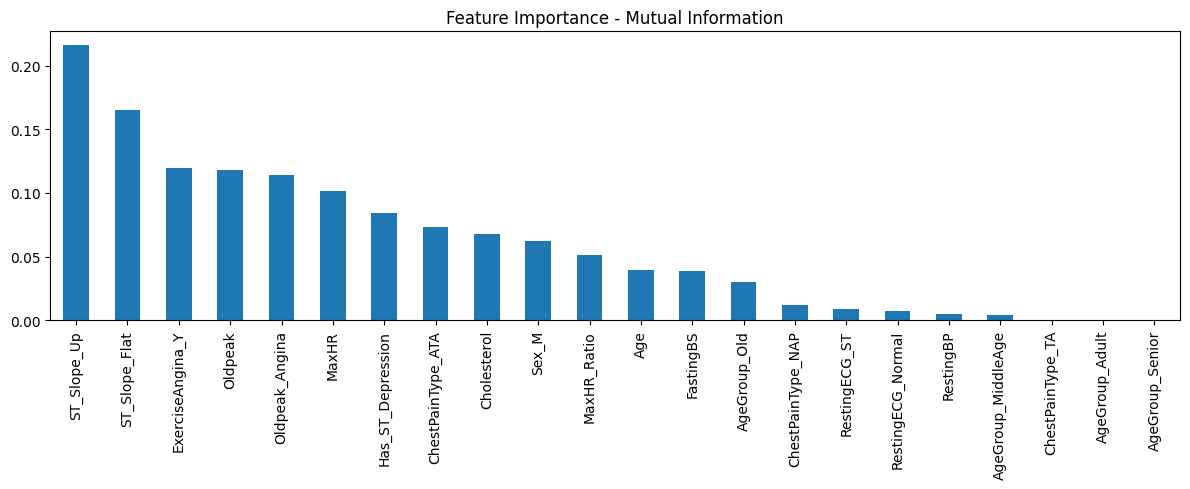

In [148]:
feature_scores.plot(
    kind='bar',
    figsize=(12, 5)
)

plt.title('Feature Importance - Mutual Information')
plt.tight_layout()
plt.show()

In [149]:
top_features = feature_scores[
    feature_scores > 0.05
]

print(top_features)

ST_Slope_Up          0.216236
ST_Slope_Flat        0.164983
ExerciseAngina_Y     0.119847
Oldpeak              0.118216
Oldpeak_Angina       0.113818
MaxHR                0.101203
Has_ST_Depression    0.084445
ChestPainType_ATA    0.072960
Cholesterol          0.067938
Sex_M                0.062198
MaxHR_Ratio          0.051549
dtype: float64


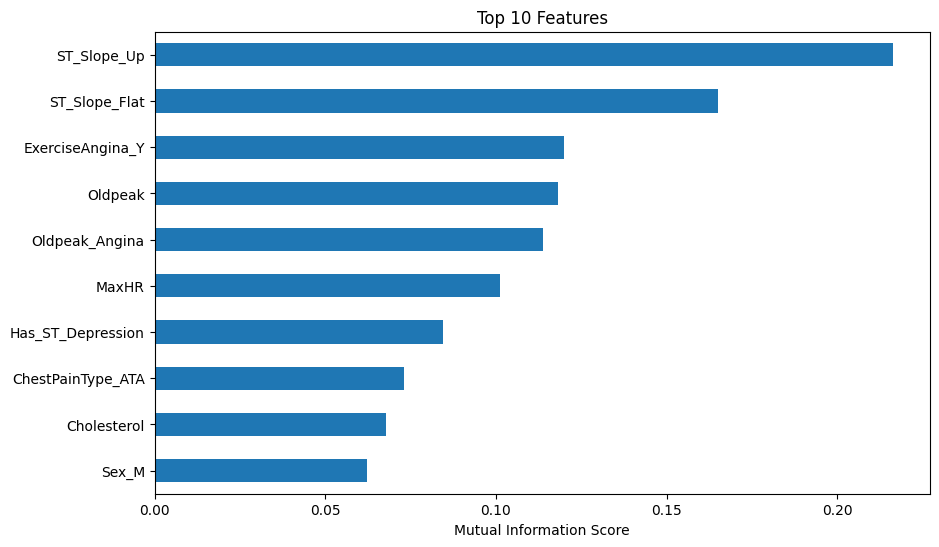

In [150]:
top_10 = feature_scores.head(10)

top_10.plot(
    kind='barh',
    figsize=(10, 6)
)

plt.title('Top 10 Features')
plt.xlabel('Mutual Information Score')
plt.gca().invert_yaxis()
plt.show()